# 08b – Streifenkorrektur mit lokalem Hintergrund (NGC 6720)

**Was:** Variante der Streifenkorrektur aus 08a, die keinen leeren Himmel braucht.

**Warum:** In 08a blieben Abschnitte, die fast ganz vom Nebel bedeckt sind, unkorrigiert – dort gibt es keine Hintergrundpixel. Genau dort (Innenraum des Rings) sieht man im Farbbild die blauen F162M-Streifen. Wenn es keinen leeren Himmel gibt, schätzen wir den Hintergrund **lokal**.

**Methode** (`astropipe.clean.destripe_local`):
1. Glattes Modell des Bildes: Median in 16 × 16-px-Zellen, bilinear hochskaliert. Es enthält die Nebelhelligkeit, aber keine Streifen (die sind nur wenige Pixel hoch). Fiji-Analogie: Rolling-Ball-Hintergrund.
2. Rest = Bild − Modell. Darin: Streifen + feine Struktur + Rauschen.
3. Starke Ausreißer im Rest (Sterne, helle Knoten, scharfe Kanten; positiv *und* negativ) maskieren.
4. Streifenprofil pro Zeile und 512-px-Abschnitt aus dem Rest, schneller Anteil wird abgezogen – wie in 08a.

**Zellgröße 16 px:** An einem künstlichen Testbild (Ring, der das Feld füllt, abschnittsweise Streifen) lag der Fehler des geschätzten Streifenprofils bei 0,14 (16 px), 0,12 (12 px), 0,16 (8 px), 0,26 (32 px), gegenüber 0,44 mit der alten Methode und 0,50 ohne Korrektur. Zu große Zellen folgen dem Nebel nicht, zu kleine enthalten selbst schon die Streifen.

**Kontrolle:** Differenzbild vorher − nachher, vor allem im Innenraum und an den Rändern des Rings: nur Streifen, keine Ringstruktur.

**Ergebnis:** _(nach dem Ausführen eintragen)_

In [1]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits

from astropipe import bands, clean

ROOT = Path("..")
RAW = ROOT / "data" / "ngc6720_nircam"
OLD = ROOT / "data" / "ngc6720_nircam_destriped"          # 08a: empty-sky method
OUT = ROOT / "data" / "ngc6720_nircam_destriped_local"    # this notebook
I2D = {bands.band_from_header(fits.getheader(f, 0)): f for f in sorted(RAW.glob("*_i2d.fits"))}
BANDS = bands.sort_bands(I2D)
BLOCK, SEG, SMOOTH = 16, 512, 51

## 1. Korrektur und Vergleich alt/neu

Die Kennzahl wird jetzt auf dem **lokalen Rest** gemessen (pro 128-px-Block). Damit sehen wir Streifen auch mitten im Nebel – dort, wo die alte Kennzahl blind war.

In [2]:
sci, old, new = {}, {}, {}
print(f"{'band':<6}{'before':>9}{'old (08a)':>11}{'new (local)':>13}")
for b in BANDS:
    sci[b] = fits.getdata(I2D[b], extname="SCI").astype(np.float32)
    old[b] = fits.getdata(OLD / I2D[b].name.replace("_i2d", "_destriped_i2d"), extname="SCI").astype(np.float32)
    new[b], _, _, _ = clean.destripe_local(sci[b], "rows", block=BLOCK, smooth=SMOOTH, segment=SEG)
    s0, s1, s2 = (clean.stripe_strength_local(x, block=BLOCK, segment=128) for x in (sci[b], old[b], new[b]))
    print(f"{b:<6}{s0:9.4f}{s1:11.4f}{s2:13.4f}")

band     before  old (08a)  new (local)
F162M    0.0884     0.0720       0.0650
F212N    0.7702     0.6302       0.5780
F300M    0.0209     0.0154       0.0142
F335M    0.0196     0.0155       0.0136


## 2. Sichtkontrolle im Innenraum des Rings

Ausschnitt um die Bildmitte (Innenraum + Ring). Oben: vorher / alt / neu. Unten: Differenzbilder (vorher − alt, vorher − neu). Im rechten Differenzbild darf **keine Ring- oder Knotenstruktur** erscheinen.

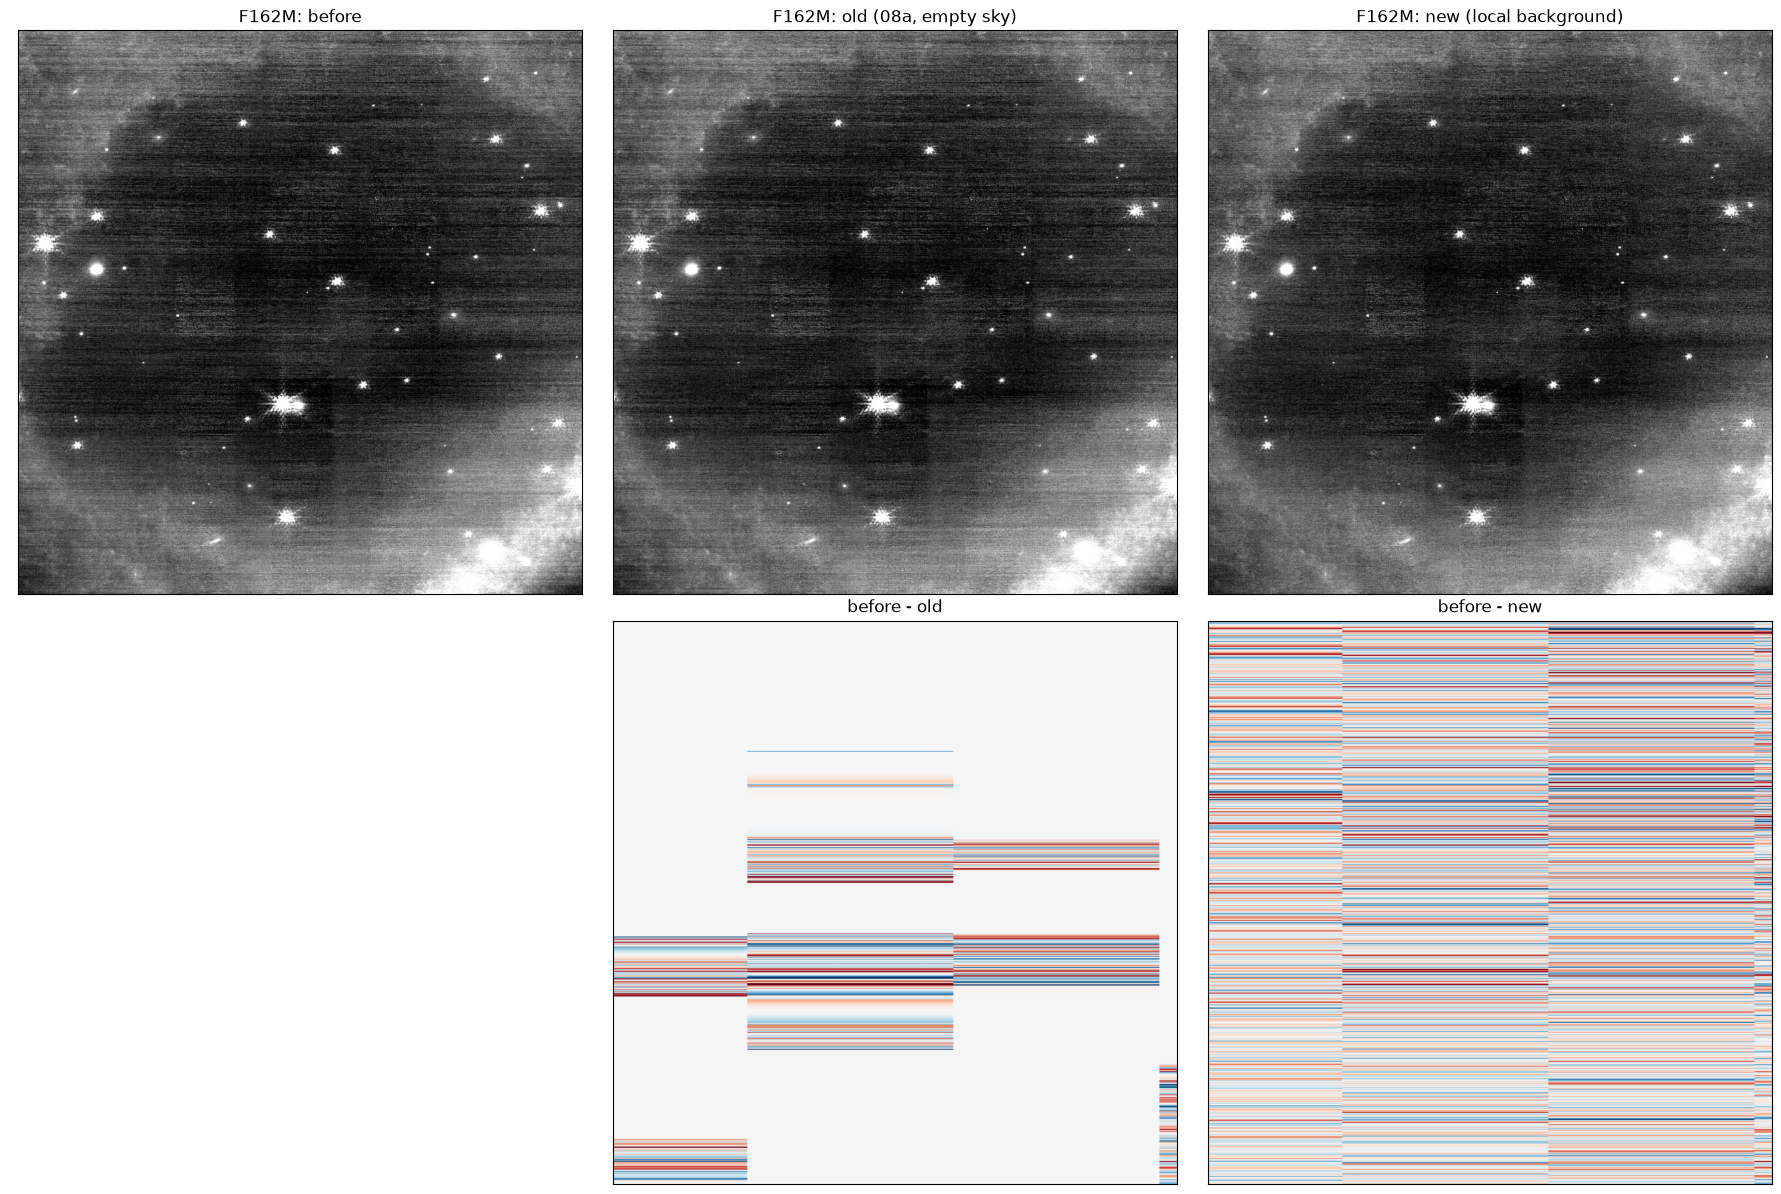

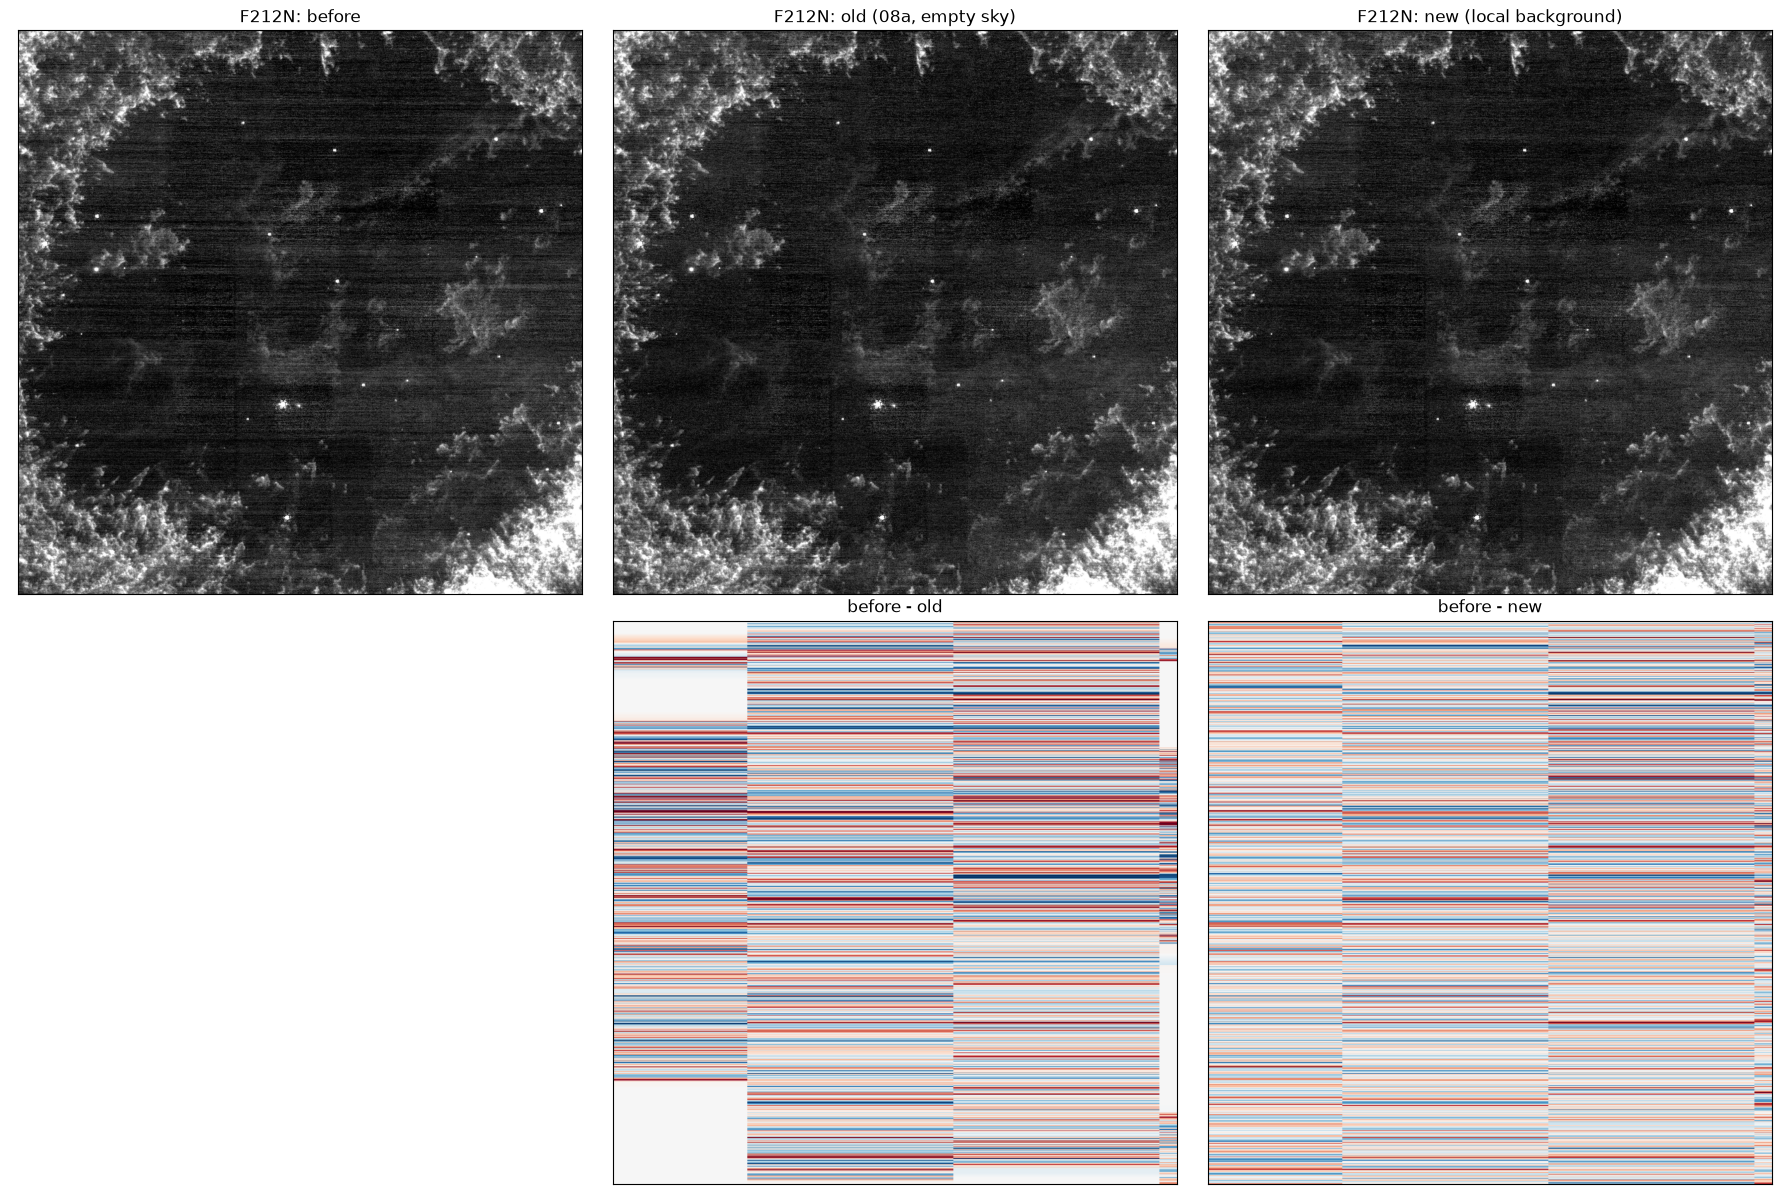

In [3]:
def look(b, half=700):
    ny, nx = sci[b].shape
    sl = np.s_[ny // 2 - half:ny // 2 + half, nx // 2 - half:nx // 2 + half]
    a, o, n = sci[b][sl], old[b][sl], new[b][sl]
    lo, hi = np.nanpercentile(a, [5, 99])
    d1, d2 = a - o, a - n
    dl = np.nanpercentile(np.abs(d2), 99)
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    for ax, img, t in zip(axes[0], (a, o, n), ("before", "old (08a, empty sky)", "new (local background)")):
        ax.imshow(img, origin="lower", cmap="gray", vmin=lo, vmax=hi); ax.set_title(f"{b}: {t}")
    axes[1, 0].axis("off")
    for ax, d, t in zip(axes[1, 1:], (d1, d2), ("before - old", "before - new")):
        ax.imshow(d, origin="lower", cmap="RdBu", vmin=-dl, vmax=dl); ax.set_title(t)
    for ax in axes.flat:
        ax.set_xticks([]); ax.set_yticks([])
    plt.tight_layout()

for b in ("F162M", "F212N"):
    look(b)

## 3. Speichern

Bereinigte Bilder nach `data/ngc6720_nircam_destriped_local/`. In Notebook 08 dann `DS` auf diesen Ordner setzen (und neues `PREFIX`, damit die Versionen getrennt bleiben).

In [4]:
for b in BANDS:
    note = f"astropipe.clean.destripe_local(axis='rows', block={BLOCK}, smooth={SMOOTH}, segment={SEG}, nsigma=5, grow_px=5)"
    print(clean.write_cleaned_i2d(I2D[b], OUT / I2D[b].name.replace("_i2d", "_destriped_i2d"), new[b], note))

../data/ngc6720_nircam_destriped_local/jw01558-o005_t001_nircam_f150w2-f162m_destriped_i2d.fits
../data/ngc6720_nircam_destriped_local/jw01558-o005_t001_nircam_clear-f212n_destriped_i2d.fits
../data/ngc6720_nircam_destriped_local/jw01558-o005_t001_nircam_clear-f300m_destriped_i2d.fits
../data/ngc6720_nircam_destriped_local/jw01558-o005_t001_nircam_clear-f335m_destriped_i2d.fits


## Fazit

- **Ausgangsproblem:** Die Streifenkorrektur aus 08a braucht leeren Himmel. Abschnitte, die vom Nebel bedeckt sind (v. a. der Innenraum in F162M), blieben unkorrigiert → blaue Streifen im Farbbild.
- **Lösung:** lokales Hintergrundmodell (Median in 16 × 16-px-Zellen, bilinear hochskaliert, wie Rolling Ball in Fiji); Streifen werden aus dem Rest *Bild − Modell* geschätzt, auch mitten im Nebel. Zellgröße 16 px nach Test an einem künstlichen Bild (Fehler 0,14 gegenüber 0,44 mit der alten Methode; 8 px und 32 px schlechter).
- **Ergebnis** (Streifenstärke auf dem lokalen Rest, pro 128-px-Block; vorher → alt → neu): F162M 0,088 → 0,072 → 0,065; F212N 0,770 → 0,630 → 0,578; F300M 0,021 → 0,015 → 0,014; F335M 0,020 → 0,016 → 0,014.
- **Sichtkontrolle:** F162M wird jetzt flächig korrigiert, der Innenraum ist sichtbar ruhiger. Differenzbilder zeigen nur waagerechte Streifen, keine Ring- oder Knotenstruktur.
- **Bleibt:** feine Reststreifen und rechteckige Detektor-Blöcke (2D-Helligkeitsstufen) – mit einer Zeilenkorrektur grundsätzlich nicht erfassbar.
- **Entscheidung:** In Notebook 08 werden die lokal korrigierten Versionen verwendet.